# Question 1: Daily Electricity Consumption Prediction
**Task:** Supervised Machine Learning – Multiple Linear Regression  
**Target Variable:** `daily_electricity_kwh` (Continuous)  
**Input Features:** `household_size`, `temperature`, `previous_usage`, `appliance_hours`  

### Marks Rubric (40 Marks):
1. **Section 1: EDA [10 Marks]** — Dataset creation, inspection, and visualization
2. **Section 2: Technique Implementation [10 Marks]** — Preprocessing & Baseline Linear Regression
3. **Section 3: Evaluate Model [10 Marks]** — MAE, MSE, RMSE, R² Score, and Residual Plot
4. **Section 4: Modify Technique Based on Requirement [10 Marks]** — Ridge Regularization & Random Forest Regressor with Hyperparameter Tuning (GridSearchCV)

In [2]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (8, 4)
print("Libraries imported successfully!")

Libraries imported successfully!


## Section 1: Exploratory Data Analysis (EDA) [10 Marks]

In [3]:
# 1.1 Simple Exam-Friendly Dataset Generation (500 samples)
np.random.seed(42)
n = 500

household_size = np.random.randint(1, 7, n)            # 1 to 6 persons
temperature = np.random.uniform(15.0, 42.0, n)         # Celsius
previous_usage = np.random.uniform(8.0, 35.0, n)       # Previous daily usage (kWh)
appliance_hours = np.random.uniform(1.0, 10.0, n)      # Running hours of appliances

# Target: Simple linear formula + realistic random noise
daily_electricity_kwh = (
    5.0 
    + 3.2 * household_size 
    + 0.4 * temperature 
    + 0.5 * previous_usage 
    + 1.8 * appliance_hours 
    + np.random.normal(0, 2.5, n)
)

df = pd.DataFrame({
    'household_size': household_size,
    'temperature': np.round(temperature, 1),
    'previous_usage': np.round(previous_usage, 1),
    'appliance_hours': np.round(appliance_hours, 1),
    'daily_electricity_kwh': np.round(daily_electricity_kwh, 2)
})

print("Dataset created! Shape:", df.shape)
df.head()

Dataset created! Shape: (500, 5)


,household_size,temperature,previous_usage,appliance_hours,daily_electricity_kwh
0,4,19.7,12.8,8.8,53.08
1,5,26.7,33.9,7.5,59.48
2,3,25.8,12.0,7.7,44.19
3,5,31.6,19.2,4.8,51.25
4,5,32.1,10.3,4.1,47.18


In [4]:
# 1.2 Dataset Inspection & Missing Values
print("=== Dataset Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Summary Statistics ===")
display(df.describe().round(2))

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   household_size         500 non-null    int64  
 1   temperature            500 non-null    float64
 2   previous_usage         500 non-null    float64
 3   appliance_hours        500 non-null    float64
 4   daily_electricity_kwh  500 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 19.7 KB

=== Missing Values ===
household_size           0
temperature              0
previous_usage           0
appliance_hours          0
daily_electricity_kwh    0
dtype: int64

=== Summary Statistics ===


,household_size,temperature,previous_usage,appliance_hours,daily_electricity_kwh
count,500.00,500.00,500.00,500.0,500.00
mean,3.50,28.54,21.39,5.5,48.35
std,1.72,7.91,8.05,2.6,8.92
min,1.00,15.10,8.20,1.0,25.73
25%,2.00,21.58,14.08,3.2,42.47
50%,4.00,28.60,21.50,5.6,48.64
75%,5.00,35.40,28.50,7.6,54.43
max,6.00,42.00,34.90,10.0,76.59


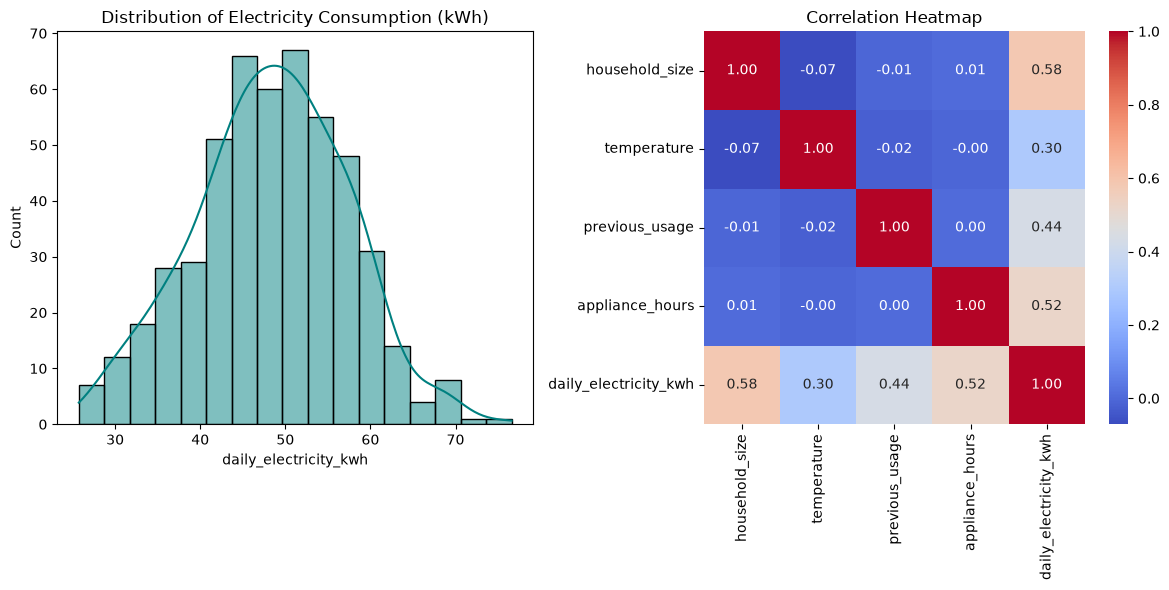

In [30]:
# 1.3 EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Distribution of Target
sns.histplot(df['daily_electricity_kwh'], kde=True, ax=axes[0], color='teal')
axes[0].set_title("Distribution of Electricity Consumption (kWh)")

# Correlation Heatmap
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## Section 2: Supervised Technique Implementation [10 Marks]

In [31]:
# 2.1 Feature-Target Split and Train-Test Split (80-20)
X = df.drop(columns=['daily_electricity_kwh'])
y = df['daily_electricity_kwh']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Feature Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (400, 4), X_test: (100, 4)


In [32]:
# 2.2 Baseline Model: Multiple Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Baseline Linear Regression trained!")
print("Intercept:", round(lr.intercept_, 2))
print("Coefficients:", dict(zip(X.columns, np.round(lr.coef_, 2))))

Baseline Linear Regression trained!
Intercept: 48.06
Coefficients: {'household_size': np.float64(5.48), 'temperature': np.float64(3.11), 'previous_usage': np.float64(3.89), 'appliance_hours': np.float64(4.61)}


## Section 3: Model Evaluation [10 Marks]

In [33]:
# 3.1 Quantitative Metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

results_lr = {
    'Model': 'Baseline Linear Regression',
    'MAE': round(mae_lr, 2),
    'MSE': round(mse_lr, 2),
    'RMSE': round(rmse_lr, 2),
    'R2 Score': round(r2_lr, 4)
}
display(pd.DataFrame([results_lr]))

,Model,MAE,MSE,RMSE,R2 Score
0,Baseline Linear Regression,1.93,6.12,2.47,0.8957


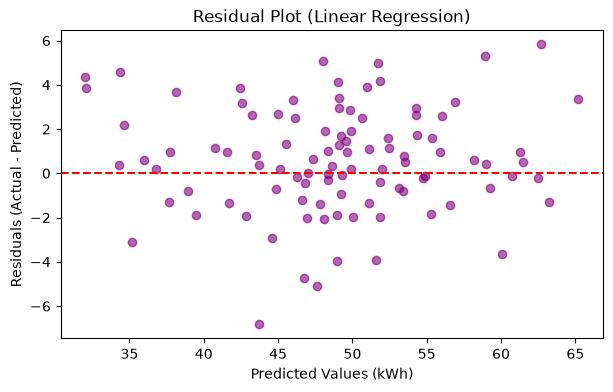

In [34]:
# 3.2 Residual Diagnostic Plot
residuals = y_test - y_pred_lr

plt.figure(figsize=(7, 4))
plt.scatter(y_pred_lr, residuals, color='purple', alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Values (kWh)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot (Linear Regression)")
plt.show()

## Section 4: Modify Technique Based on Requirement [10 Marks]
**Modifications Applied (from Lab 10):**
1. **Regularization:** Ridge Regression ($L_2$ penalty) to reduce variance.
2. **Advanced Model & Hyperparameter Tuning:** `RandomForestRegressor` with `GridSearchCV` to optimize `max_depth` and `n_estimators`.
3. **Feature Importance:** Visualizing which features most strongly drive electricity consumption.

In [35]:
# 4.1 Modification A: Ridge Regression (L2 Regularization)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

results_ridge = {
    'Model': 'Ridge Regression (L2)',
    'MAE': round(mean_absolute_error(y_test, y_pred_ridge), 2),
    'MSE': round(mean_squared_error(y_test, y_pred_ridge), 2),
    'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_ridge)), 2),
    'R2 Score': round(r2_score(y_test, y_pred_ridge), 4)
}

In [36]:
# 4.2 Modification B: Tuned Random Forest Regressor (GridSearchCV)
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [4, 6, 8]
}

grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2')
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test)

results_rf = {
    'Model': f"Tuned Random Forest {grid_rf.best_params_}",
    'MAE': round(mean_absolute_error(y_test, y_pred_rf), 2),
    'MSE': round(mean_squared_error(y_test, y_pred_rf), 2),
    'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 2),
    'R2 Score': round(r2_score(y_test, y_pred_rf), 4)
}

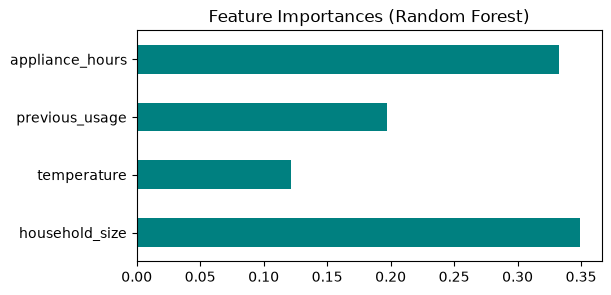

=== Final Model Comparison Table ===


,Model,MAE,MSE,RMSE,R2 Score
0,Baseline Linear Regression,1.93,6.12,2.47,0.8957
1,Ridge Regression (L2),1.93,6.12,2.47,0.8956
2,"Tuned Random Forest {'max_depth': 8, 'n_estima...",2.42,9.05,3.01,0.8458


In [37]:
# 4.3 Feature Importance & Side-by-Side Comparison Table
fig, ax = plt.subplots(figsize=(6, 3))
feat_importances = pd.Series(best_rf.feature_importances_, index=X.columns)
feat_importances.plot(kind='barh', color='teal', ax=ax)
ax.set_title("Feature Importances (Random Forest)")
plt.show()

# Final Comparison Table
comparison_df = pd.DataFrame([results_lr, results_ridge, results_rf])
print("=== Final Model Comparison Table ===")
display(comparison_df)